# Análisis de resultados: CPU vs CUDA

Este notebook lee los benchmarks oficiales de `results/benchmarks/` (10 épocas, batch 32,
3 repeticiones, seed 42, `num_workers=0`) y genera las tablas y figuras del informe.

- **CPU:** Intel Core i7-9750H (6 núcleos / 12 hilos), PyTorch 2.6.0+cpu.
- **GPU:** NVIDIA GeForce GTX 1650 (4 GB, compute capability 7.5), PyTorch 2.6.0+cu126.

Las figuras se guardan en `reports/figures/` y las tablas en `reports/tablas/`.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
BENCH = ROOT / "results" / "benchmarks"
FIG_DIR = ROOT / "reports" / "figures"
TAB_DIR = ROOT / "reports" / "tablas"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)


def latest_full_run(device: str) -> Path:
    """Último directorio oficial válido (full_protocol y completed) del dispositivo."""
    candidates = []
    for run_dir in sorted((BENCH / device).iterdir()):
        meta_path = run_dir / "benchmark.json"
        if not meta_path.is_file():
            continue
        meta = json.loads(meta_path.read_text(encoding="utf-8"))
        if meta.get("status") == "completed" and meta["protocol"].get("full_protocol"):
            candidates.append(run_dir)
    if not candidates:
        raise FileNotFoundError(f"No hay benchmark oficial para {device}")
    return candidates[-1]


RUN_DIRS = {d: latest_full_run(d) for d in ("cpu", "cuda")}
epochs = pd.concat([pd.read_csv(p / "epochs.csv") for p in RUN_DIRS.values()], ignore_index=True)
runs = pd.concat([pd.read_csv(p / "runs.csv") for p in RUN_DIRS.values()], ignore_index=True)
meta = {d: json.loads((p / "benchmark.json").read_text(encoding="utf-8")) for d, p in RUN_DIRS.items()}
for d, p in RUN_DIRS.items():
    print(f"{d:>4}: {p.relative_to(ROOT)}")
print(epochs.shape, runs.shape)

 cpu: results\benchmarks\cpu\20261113T190032Z_cpu
cuda: results\benchmarks\cuda\20261113T192058Z_cuda
(60, 32) (6, 28)


## Estilo de las figuras

Dos series fijas en todo el notebook: **CPU = azul**, **CUDA = naranja** (slots 1 y 2 de una
paleta categórica validada para daltonismo). Ejes y cuadrícula en gris claro; los valores se
rotulan directamente sobre las barras.

In [2]:
COLORS = {"cpu": "#2a78d6", "cuda": "#eb6834"}
LABELS = {"cpu": "CPU (i7-9750H)", "cuda": "CUDA (GTX 1650)"}
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2,
})


def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, bbox_inches="tight")
    print("Guardado:", path.relative_to(ROOT))

## 1. Tiempo total por repetición

`measured_execution_s` = restauración del modelo + 10 épocas (entrenamiento y validación) +
evaluación final en test. Excluye el warm-up de 2 batches.

In [3]:
per_rep = runs.pivot(index="repetition", columns="device", values="measured_execution_s")
summary = pd.DataFrame({
    "media_s": per_rep.mean(), "desv_s": per_rep.std(ddof=1),
    "min_s": per_rep.min(), "max_s": per_rep.max(),
})
summary["cv_%"] = 100 * summary["desv_s"] / summary["media_s"]
SPEEDUP_TOTAL = summary.loc["cpu", "media_s"] / summary.loc["cuda", "media_s"]

tabla_tiempos = per_rep.rename(columns=LABELS).round(2)
tabla_tiempos.loc["Media"] = per_rep.mean().rename(LABELS).round(2)
tabla_tiempos.loc["Desv. estándar"] = per_rep.std(ddof=1).rename(LABELS).round(2)
tabla_tiempos.to_csv(TAB_DIR / "tiempos_por_repeticion.csv", encoding="utf-8")
display(tabla_tiempos)
display(summary.round(2))
print(f"Speedup total (media CPU / media CUDA): {SPEEDUP_TOTAL:.2f}x")

device,CPU (i7-9750H),CUDA (GTX 1650)
repetition,,
1,402.84,95.34
2,408.54,96.65
3,405.49,97.00
Media,405.62,96.33
Desv. estándar,2.85,0.87


,media_s,desv_s,min_s,max_s,cv_%
device,,,,,
cpu,405.62,2.85,402.84,408.54,0.7
cuda,96.33,0.87,95.34,97.00,0.9


Speedup total (media CPU / media CUDA): 4.21x


Guardado: reports\figures\01_tiempo_por_repeticion.png


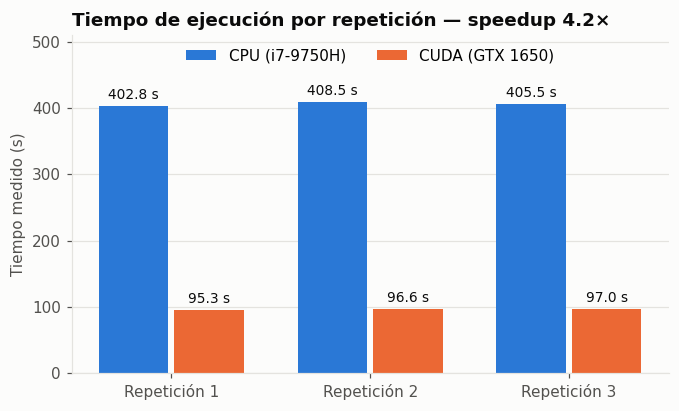

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(per_rep.index))
w = 0.38
for i, d in enumerate(("cpu", "cuda")):
    bars = ax.bar(x + (i - 0.5) * w, per_rep[d], w - 0.03, color=COLORS[d], label=LABELS[d])
    ax.bar_label(bars, fmt="%.1f s", padding=3, color=INK, fontsize=9)
ax.set_xticks(x, [f"Repetición {r}" for r in per_rep.index])
ax.set_ylabel("Tiempo medido (s)")
ax.set_title(f"Tiempo de ejecución por repetición — speedup {SPEEDUP_TOTAL:.1f}×")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, per_rep.values.max() * 1.25)
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
save(fig, "01_tiempo_por_repeticion.png")
plt.show()

## 2. Tiempo por fase y speedup por fase

Cada fase se suma sobre las 10 épocas de una repetición y luego se promedia entre las 3
repeticiones. `overhead` es el tiempo de pared de la época que no cae en ninguna fase medida
(bucle de Python, logging). `validación` es la evaluación completa sobre 2,610 imágenes
después de cada época. En CUDA cada fase se mide con `torch.cuda.synchronize()`, así que el
tiempo de cada kernel se atribuye a su propia fase.

In [5]:
PHASES = {
    "Carga de datos (CPU)": "train_load_cpu_s",
    "Transferencia host→device": "train_transfer_s",
    "Data augmentation": "train_augmentation_s",
    "zero_grad": "train_zero_grad_s",
    "Forward": "train_forward_s",
    "Loss": "train_loss_s",
    "Backward": "train_backward_s",
    "Optimizador (Adam)": "train_optimizer_s",
    "Métricas": "train_metrics_s",
    "Overhead no atribuido": "train_unattributed_overhead_s",
    "Validación por época": "val_evaluation_wall_s",
}
per_run = epochs.groupby(["device", "repetition"])[list(PHASES.values())].sum()
phase_mean = per_run.groupby("device").mean().T
phase_std = per_run.groupby("device").std(ddof=1).T
phase_mean.index = phase_std.index = list(PHASES)

test_eval = runs.groupby("device")["final_evaluation_wall_s"]
phase_mean.loc["Evaluación final (test)"] = test_eval.mean()
phase_std.loc["Evaluación final (test)"] = test_eval.std(ddof=1)
phase_mean.loc["TOTAL medido"] = runs.groupby("device")["measured_execution_s"].mean()
phase_std.loc["TOTAL medido"] = runs.groupby("device")["measured_execution_s"].std(ddof=1)

tabla_fases = pd.DataFrame({
    "CPU media (s)": phase_mean["cpu"], "CPU desv (s)": phase_std["cpu"],
    "CUDA media (s)": phase_mean["cuda"], "CUDA desv (s)": phase_std["cuda"],
    "Speedup (CPU/CUDA)": phase_mean["cpu"] / phase_mean["cuda"],
    "% del total CPU": 100 * phase_mean["cpu"] / phase_mean.loc["TOTAL medido", "cpu"],
    "% del total CUDA": 100 * phase_mean["cuda"] / phase_mean.loc["TOTAL medido", "cuda"],
})
tabla_fases.round(3).to_csv(TAB_DIR / "tiempos_y_speedup_por_fase.csv", encoding="utf-8")
display(tabla_fases.round(2))

,CPU media (s),CPU desv (s),CUDA media (s),CUDA desv (s),Speedup (CPU/CUDA),% del total CPU,% del total CUDA
Carga de datos (CPU),17.39,0.22,17.94,0.40,0.97,4.29,18.62
Transferencia host→device,0.05,0.00,0.96,0.00,0.05,0.01,0.99
Data augmentation,17.29,0.23,15.95,0.49,1.08,4.26,16.56
zero_grad,0.60,0.01,0.76,0.00,0.79,0.15,0.79
Forward,163.08,1.46,15.66,0.09,10.41,40.21,16.26
Loss,0.28,0.01,0.80,0.01,0.35,0.07,0.83
Backward,166.12,0.82,28.80,0.04,5.77,40.95,29.90
Optimizador (Adam),6.76,0.10,4.05,0.03,1.67,1.67,4.21
Métricas,0.35,0.00,1.70,0.03,0.20,0.09,1.77
Overhead no atribuido,0.33,0.01,1.21,0.02,0.27,0.08,1.26


Guardado: reports\figures\02_tiempo_por_fase.png


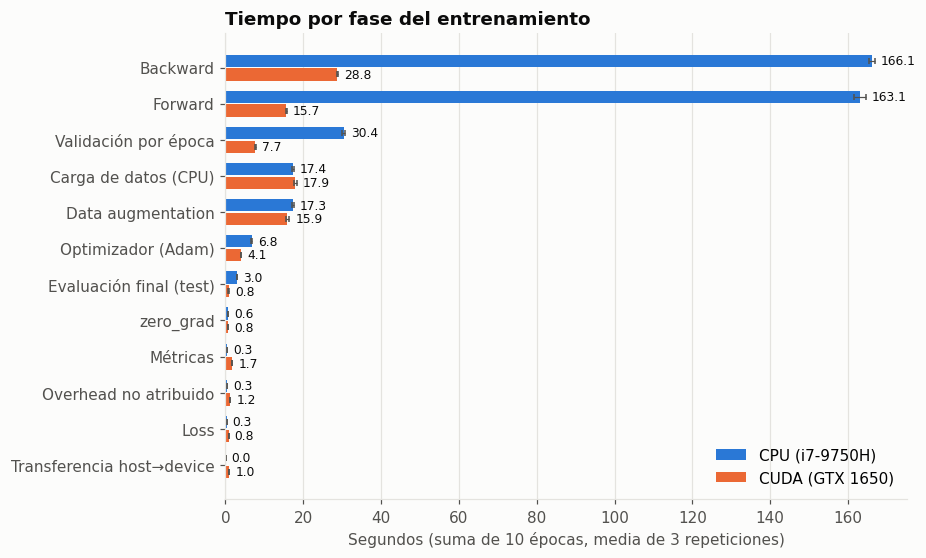

In [6]:
plot_phases = [p for p in tabla_fases.index if p != "TOTAL medido"]
order = tabla_fases.loc[plot_phases, "CPU media (s)"].sort_values().index
fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(order))
h = 0.38
for i, d in enumerate(("cpu", "cuda")):
    vals = phase_mean.loc[order, d]
    err = phase_std.loc[order, d]
    bars = ax.barh(y + (0.5 - i) * h, vals, h - 0.04, xerr=err, color=COLORS[d], label=LABELS[d],
                   error_kw={"ecolor": INK_2, "elinewidth": 0.8, "capsize": 2})
    ax.bar_label(bars, fmt="%.1f", padding=4, color=INK, fontsize=8)
ax.set_yticks(y, order)
ax.set_xlabel("Segundos (suma de 10 épocas, media de 3 repeticiones)")
ax.set_title("Tiempo por fase del entrenamiento")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save(fig, "02_tiempo_por_fase.png")
plt.show()

Guardado: reports\figures\03_speedup_por_fase.png


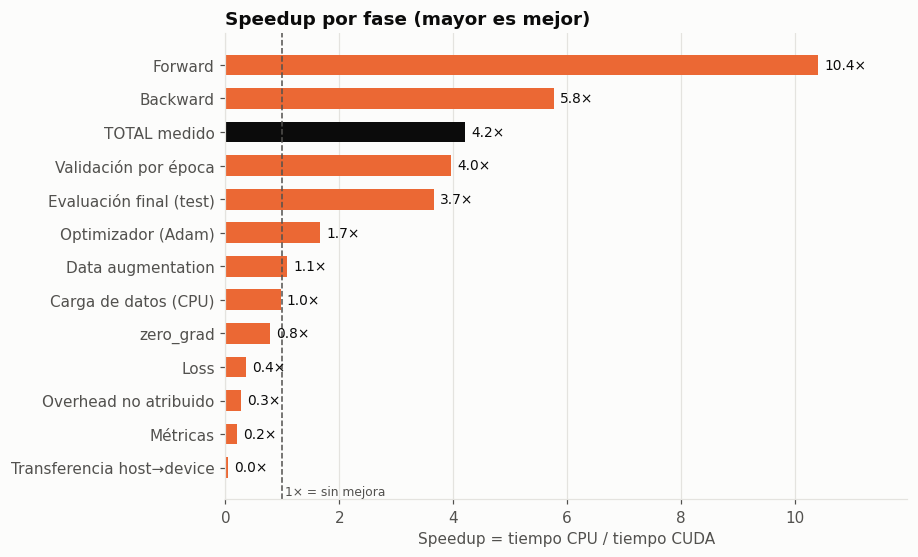

In [7]:
sp = tabla_fases.loc[plot_phases + ["TOTAL medido"], "Speedup (CPU/CUDA)"].sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = [INK if name == "TOTAL medido" else COLORS["cuda"] for name in sp.index]
bars = ax.barh(sp.index, sp.values, 0.62, color=colors)
ax.bar_label(bars, labels=[f"{v:.1f}×" for v in sp.values], padding=4, color=INK, fontsize=9)
ax.axvline(1, color=INK_2, linewidth=1, linestyle="--")
ax.text(1.05, -0.9, "1× = sin mejora", color=INK_2, fontsize=8, va="bottom")
ax.set_xlabel("Speedup = tiempo CPU / tiempo CUDA")
ax.set_title("Speedup por fase (mayor es mejor)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, sp.max() * 1.15)
save(fig, "03_speedup_por_fase.png")
plt.show()

## 3. Composición de una época

Qué fracción del tiempo de pared de una época (entrenamiento + validación) ocupa cada grupo de
fases. Sirve para ver qué queda como cuello de botella cuando la matemática de la red pasa a la
GPU.

device,cpu,cuda
"Matemática de la red\n(forward, loss, backward, Adam)",83.7,52.4
Data augmentation,4.3,16.7
Carga + transferencia,4.3,19.8
Validación,7.5,8.0
Métricas + overhead,0.2,3.1


Guardado: reports\figures\04_composicion_por_dispositivo.png


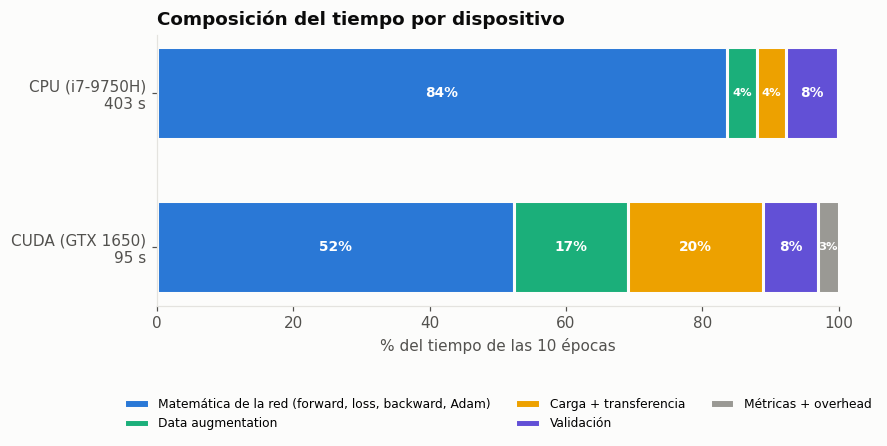

In [8]:
GROUPS = {
    "Matemática de la red\n(forward, loss, backward, Adam)": ["Forward", "Loss", "Backward", "Optimizador (Adam)", "zero_grad"],
    "Data augmentation": ["Data augmentation"],
    "Carga + transferencia": ["Carga de datos (CPU)", "Transferencia host→device"],
    "Validación": ["Validación por época"],
    "Métricas + overhead": ["Métricas", "Overhead no atribuido"],
}
comp = pd.DataFrame({g: phase_mean.loc[cols].sum() for g, cols in GROUPS.items()}).T
comp_pct = 100 * comp / comp.sum()
display(comp_pct.round(1))

GROUP_COLORS = ["#2a78d6", "#1baf7a", "#eda100", "#6250d6", "#9a9994"]
fig, ax = plt.subplots(figsize=(8, 3.2))
for row, d in enumerate(("cpu", "cuda")):
    left = 0.0
    for (g, color) in zip(comp_pct.index, GROUP_COLORS):
        v = comp_pct.loc[g, d]
        ax.barh(row, v, 0.6, left=left, color=color, edgecolor=SURFACE, linewidth=2,
                label=g.replace("\n", " ") if row == 0 else None)
        if v >= 3:
            ax.text(left + v / 2, row, f"{v:.0f}%", ha="center", va="center", color="white",
                    fontsize=9 if v >= 6 else 7.5, fontweight="bold")
        left += v
ax.set_yticks([0, 1], [f"{LABELS[d]}\n{comp[d].sum():.0f} s" for d in ("cpu", "cuda")])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% del tiempo de las 10 épocas")
ax.set_title("Composición del tiempo por dispositivo")
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, fontsize=8)
save(fig, "04_composicion_por_dispositivo.png")
plt.show()

## 4. Tiempo por época

Pared de entrenamiento + validación de cada época, promediada entre repeticiones. Una línea
plana indica que el tiempo por época es estable (sin calentamiento ni *thermal throttling*
apreciable).

Guardado: reports\figures\05_tiempo_por_epoca.png


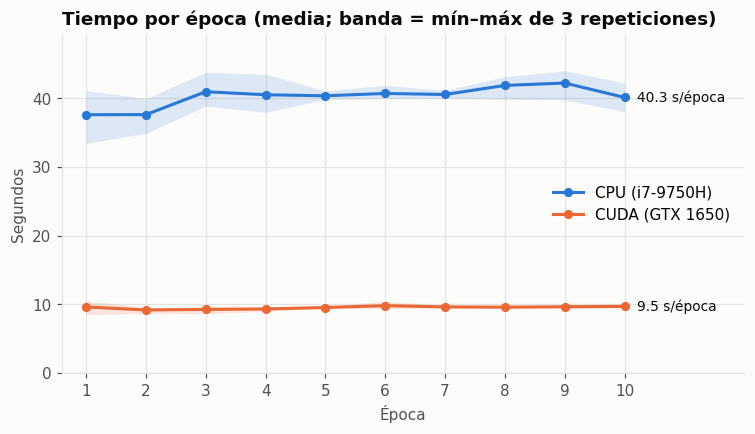

In [9]:
epochs["epoch_total_s"] = epochs["train_epoch_wall_s"] + epochs["val_evaluation_wall_s"]
ep = epochs.groupby(["device", "epoch"])["epoch_total_s"].agg(["mean", "min", "max"]).reset_index()
fig, ax = plt.subplots(figsize=(8, 4))
for d in ("cpu", "cuda"):
    s = ep[ep.device == d]
    ax.fill_between(s.epoch, s["min"], s["max"], color=COLORS[d], alpha=0.15, linewidth=0)
    ax.plot(s.epoch, s["mean"], color=COLORS[d], marker="o", markersize=5, label=LABELS[d])
    ax.annotate(f"{s['mean'].mean():.1f} s/época", (s.epoch.iloc[-1], s["mean"].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax.set_xticks(range(1, 11))
ax.set_xlim(0.6, 12)
ax.set_ylim(0, ep["max"].max() * 1.12)
ax.set_xlabel("Época")
ax.set_ylabel("Segundos")
ax.set_title("Tiempo por época (media; banda = mín–máx de 3 repeticiones)")
ax.legend(loc="center right")
save(fig, "05_tiempo_por_epoca.png")
plt.show()

## 5. Calidad del modelo

El speedup solo tiene sentido si el modelo aprende igual en ambos dispositivos. En CPU las tres
repeticiones son idénticas (operaciones deterministas con la misma semilla). En CUDA varían
porque cuDNN elige algoritmos no deterministas (sumas atómicas en paralelo en el orden en que
terminan los hilos) y el generador aleatorio de la GPU produce otra secuencia de
augmentation.

Guardado: reports\figures\06_curvas_validacion.png


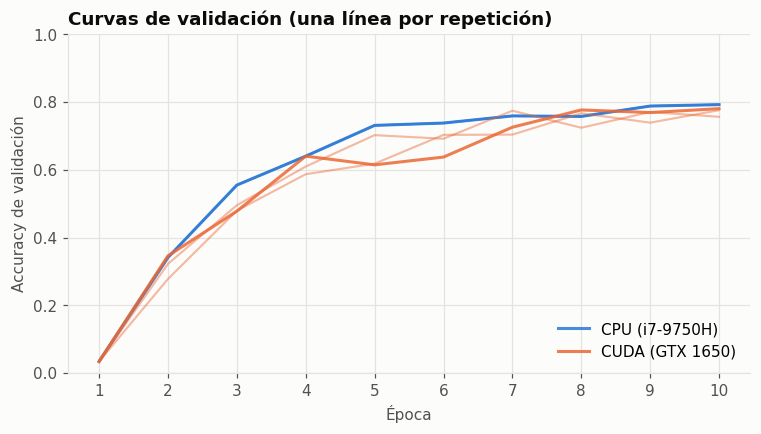

,device,repetition,test_accuracy,test_f1_macro
0,cpu,1,0.8211,0.8233
1,cpu,2,0.8211,0.8233
2,cpu,3,0.8211,0.8233
3,cuda,1,0.7498,0.7433
4,cuda,2,0.7184,0.7056
5,cuda,3,0.7981,0.7963


test_accuracy                         test_f1_macro                  \
                mean     std     min     max          mean     std     min   
device                                                                       
cpu           0.8211  0.0000  0.8211  0.8211        0.8233  0.0000  0.8233   
cuda          0.7554  0.0401  0.7184  0.7981        0.7484  0.0455  0.7056   

                
           max  
device          
cpu     0.8233  
cuda    0.7963

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for d in ("cpu", "cuda"):
    for rep, s in epochs[epochs.device == d].groupby("repetition"):
        ax.plot(s.epoch, s.val_accuracy, color=COLORS[d], alpha=0.85 if rep == 1 else 0.45,
                linewidth=2 if rep == 1 else 1.4, label=LABELS[d] if rep == 1 else None)
ax.set_xticks(range(1, 11))
ax.set_ylim(0, 1)
ax.set_xlabel("Época")
ax.set_ylabel("Accuracy de validación")
ax.set_title("Curvas de validación (una línea por repetición)")
ax.legend(loc="lower right")
save(fig, "06_curvas_validacion.png")
plt.show()

calidad = runs.groupby("device")[["test_accuracy", "test_f1_macro"]].agg(["mean", "std", "min", "max"])
calidad.round(4).to_csv(TAB_DIR / "calidad_test.csv", encoding="utf-8")
display(runs[["device", "repetition", "test_accuracy", "test_f1_macro"]].round(4))
display(calidad.round(4))

## 6. Resumen para el informe

In [11]:
def fila(p):
    r = tabla_fases.loc[p]
    return f"| {p} | {r['CPU media (s)']:.2f} | {r['CUDA media (s)']:.2f} | {r['Speedup (CPU/CUDA)']:.2f}× |"

lineas = ["| Fase | CPU (s) | CUDA (s) | Speedup |", "|---|---:|---:|---:|"]
lineas += [fila(p) for p in tabla_fases.index]
print("\n".join(lineas))
print()
print(f"Speedup total: {SPEEDUP_TOTAL:.2f}x "
      f"({summary.loc['cpu','media_s']:.1f} s -> {summary.loc['cuda','media_s']:.1f} s)")
mem = meta["cuda"]["hardware"]["gpu"]
print(f"GPU: {mem['name']}, {mem['total_memory_bytes']/2**30:.1f} GiB, driver {mem['driver_version']}")

| Fase | CPU (s) | CUDA (s) | Speedup |
|---|---:|---:|---:|
| Carga de datos (CPU) | 17.39 | 17.94 | 0.97× |
| Transferencia host→device | 0.05 | 0.96 | 0.05× |
| Data augmentation | 17.29 | 15.95 | 1.08× |
| zero_grad | 0.60 | 0.76 | 0.79× |
| Forward | 163.08 | 15.66 | 10.41× |
| Loss | 0.28 | 0.80 | 0.35× |
| Backward | 166.12 | 28.80 | 5.77× |
| Optimizador (Adam) | 6.76 | 4.05 | 1.67× |
| Métricas | 0.35 | 1.70 | 0.20× |
| Overhead no atribuido | 0.33 | 1.21 | 0.27× |
| Validación por época | 30.39 | 7.67 | 3.96× |
| Evaluación final (test) | 2.97 | 0.81 | 3.66× |
| TOTAL medido | 405.62 | 96.33 | 4.21× |

Speedup total: 4.21x (405.6 s -> 96.3 s)
GPU: NVIDIA GeForce GTX 1650, 4.0 GiB, driver 610.47
